# Task 3: ML vs DL Model Comparison

## Objective

Compare the best ML model from **Task 2** (Tuned SVM + HOG) against the best DL model from **Task 1** (ResNet-50 Fine-Tuned) on the same CIFAR-10 test set. Both models were trained and evaluated on an identical stratified data split (SEED=42, 8,000 train / 2,000 val / 10,000 test) to ensure a fair comparison.

---

## Section 1: Environment Setup

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck']

# Consistent colour scheme for ML vs DL across all plots
ML_COLOR = '#FF9800'
DL_COLOR = '#1E88E5'

print('All libraries imported successfully.')
print(f'Classes: {CLASSES}')

All libraries imported successfully.
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## Section 2: Results Summary

Results are hardcoded from the final outputs of Task 1 (development_DL.ipynb) and Task 2 (development_ML.ipynb). Both were evaluated on the same 10,000-image official CIFAR-10 test split.

In [8]:
# ── Results from Task 1: development_DL-2.ipynb ──────────────────────────────
dl_results = {
    'Model':            'ResNet-50 Fine-Tuned (DL)',
    'Task':             'Task 1',
    'Framework':        'PyTorch (ImageNet-1K pre-trained)',
    'Accuracy':          0.9151,
    'Precision':         0.9156,
    'Recall':            0.9151,
    'F1-Score':          0.9151,
    'Train Time (s)':    30490,
    'Training Samples':  8000,
    'Test Samples':      10000,
    'Feature Method':   'End-to-end CNN (learnt features)',
}

# ── Results from Task 2: development-ML-improved.ipynb ───────────────────────
ml_results = {
    'Model':            'Tuned SVM RBF + HOG (ML)',
    'Task':             'Task 2',
    'Framework':        'scikit-learn (SVC, C=10, gamma=scale)',
    'Accuracy':          0.5366,
    'Precision':         0.5373,
    'Recall':            0.5366,
    'F1-Score':          0.5365,
    'Train Time (s)':    119.2,
    'Training Samples':  8000,
    'Test Samples':      10000,
    'Feature Method':   'HOG (1,764-dim hand-crafted features)',
}

# ── Summary DataFrame ────────────────────────────────────────────────────────
summary_df = pd.DataFrame([ml_results, dl_results]).set_index('Model')
display_cols = ['Task', 'Accuracy', 'Precision', 'Recall',
                'F1-Score', 'Train Time (s)', 'Feature Method']

print('=' * 70)
print('TASK 3: ML vs DL Comparison — CIFAR-10 Test Set (10,000 images)')
print('=' * 70)
print(summary_df[display_cols].to_string(float_format='{:.4f}'.format))
print()

abs_gap = (dl_results['Accuracy'] - ml_results['Accuracy']) * 100
rel_gap = abs_gap / (ml_results['Accuracy'] * 100) * 100
print(f"Absolute Accuracy Improvement (DL over ML): +{abs_gap:.2f}%")
print(f"Relative Accuracy Improvement (DL over ML): +{rel_gap:.1f}%")
print('=' * 70)

TASK 3: ML vs DL Comparison — CIFAR-10 Test Set (10,000 images)
                             Task  Accuracy  Precision  Recall  F1-Score  Train Time (s)                         Feature Method
Model                                                                                                                          
Tuned SVM RBF + HOG (ML)   Task 2    0.5366     0.5373  0.5366    0.5365        119.2000  HOG (1,764-dim hand-crafted features)
ResNet-50 Fine-Tuned (DL)  Task 1    0.9151     0.9156  0.9151    0.9151      30490.0000       End-to-end CNN (learnt features)

Absolute Accuracy Improvement (DL over ML): +37.85%
Relative Accuracy Improvement (DL over ML): +70.5%


## Section 3: Figure 1: Overall Performance Comparison

Side-by-side bar chart comparing Accuracy, Precision, Recall, and F1-Score for both models on the CIFAR-10 test set.

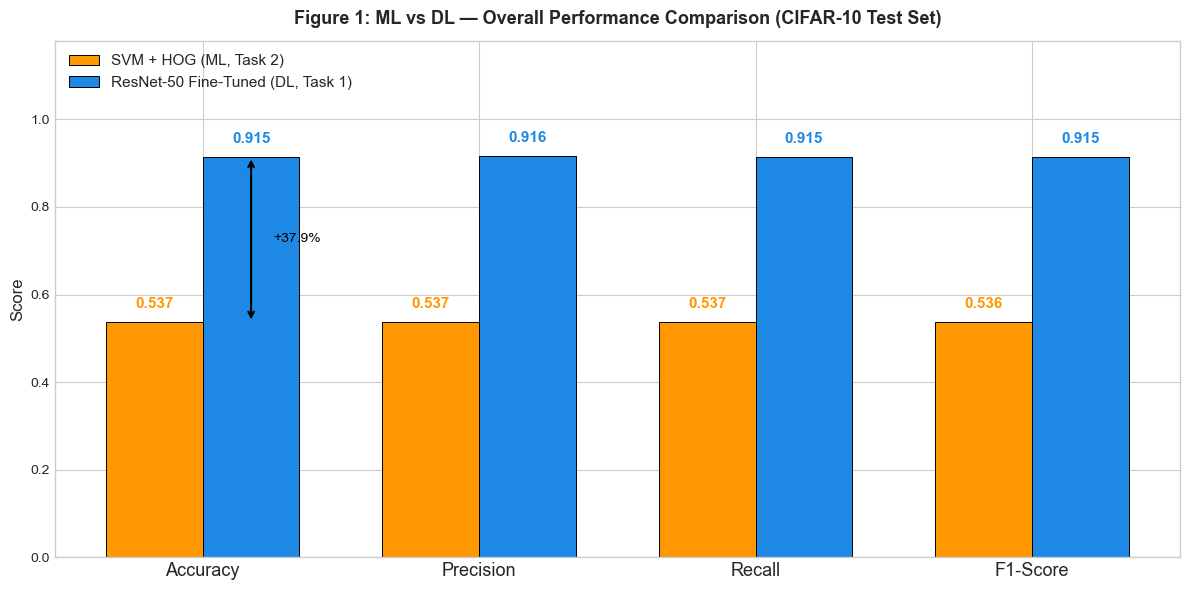

In [11]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
ml_vals = [ml_results['Accuracy'],  ml_results['Precision'],
           ml_results['Recall'],    ml_results['F1-Score']]
dl_vals = [dl_results['Accuracy'],  dl_results['Precision'],
           dl_results['Recall'],    dl_results['F1-Score']]

x = np.arange(len(metrics))
w = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
b1 = ax.bar(x - w/2, ml_vals, w, label='SVM + HOG (ML, Task 2)',
            color=ML_COLOR, edgecolor='black', linewidth=0.7)
b2 = ax.bar(x + w/2, dl_vals, w, label='ResNet-50 Fine-Tuned (DL, Task 1)',
            color=DL_COLOR, edgecolor='black', linewidth=0.7)

ax.set_ylim(0, 1.18)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=13)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Figure 1: ML vs DL — Overall Performance Comparison (CIFAR-10 Test Set)',
             fontsize=13, fontweight='bold', pad=12)
ax.legend(fontsize=11, loc='upper left')

for bar in b1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.025,
            f'{bar.get_height():.3f}', ha='center', va='bottom',
            fontsize=11, fontweight='bold', color=ML_COLOR)
for bar in b2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.025,
            f'{bar.get_height():.3f}', ha='center', va='bottom',
            fontsize=11, fontweight='bold', color=DL_COLOR)

# Annotate the accuracy gap
ax.annotate('', xy=(x[0] + w/2, dl_vals[0]), xytext=(x[0] + w/2, ml_vals[0]),
            arrowprops=dict(arrowstyle='<->', color='black', lw=1.5))
ax.text(x[0] + w/2 + 0.08, (dl_vals[0] + ml_vals[0])/2,
        f'+{abs_gap:.1f}%', fontsize=10, va='center', color='black')

plt.tight_layout()
plt.show()

## Section 4: Figure 2: Per-Class Accuracy Comparison

Recall values per class from the classification reports of both models, showing which classes benefit most from deep learning.

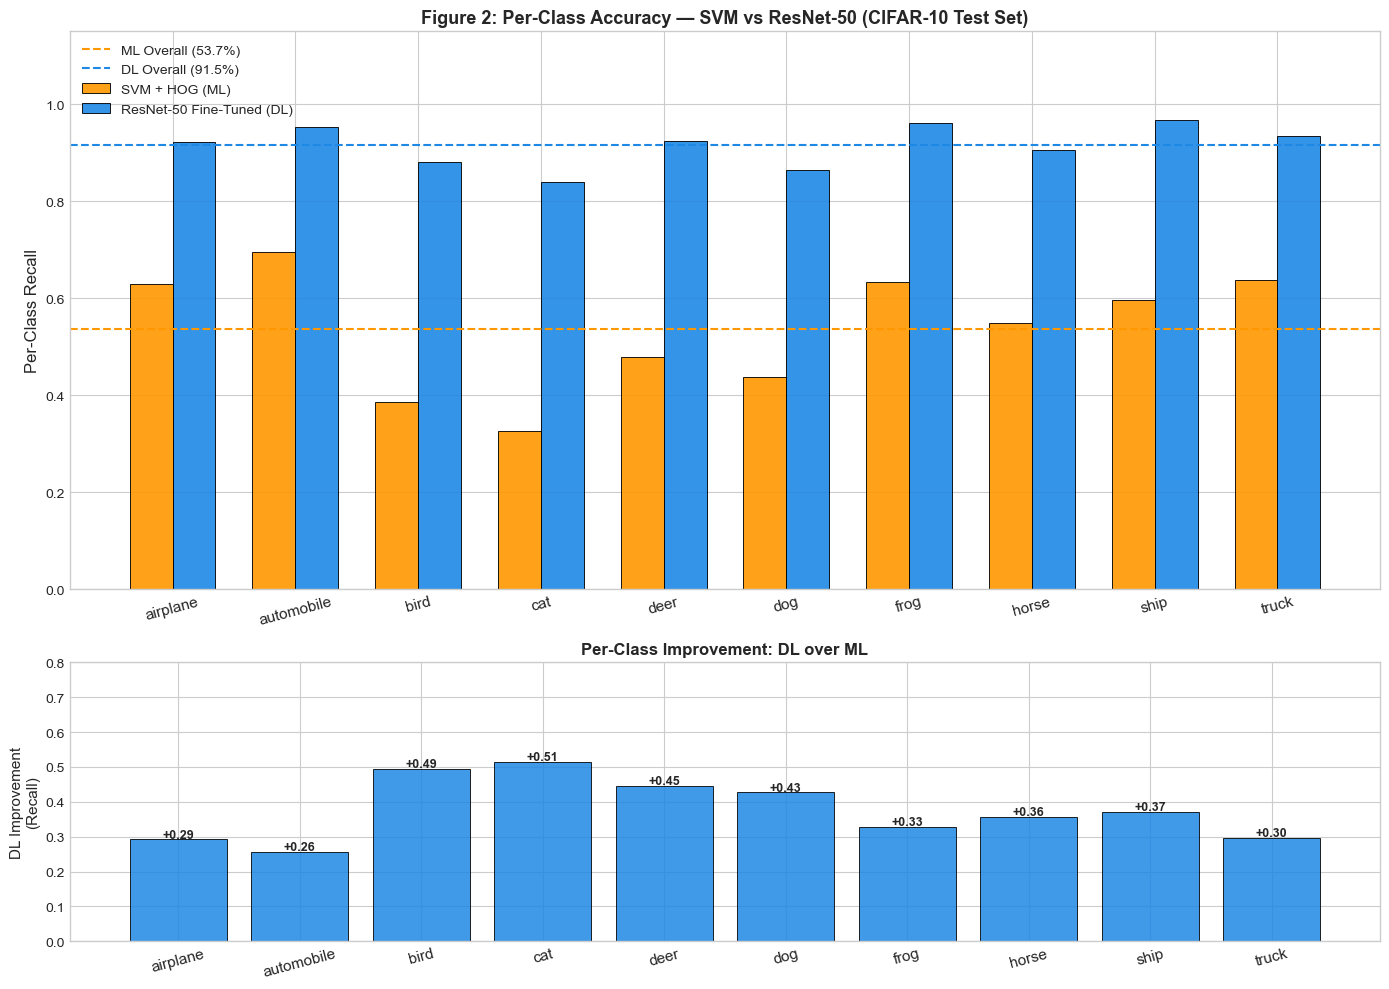


Ranked per-class improvement (DL over ML):
  cat         : +0.515 (+51.5%)
  bird        : +0.495 (+49.5%)
  deer        : +0.445 (+44.5%)
  dog         : +0.427 (+42.7%)
  ship        : +0.372 (+37.2%)
  horse       : +0.357 (+35.7%)
  frog        : +0.328 (+32.8%)
  truck       : +0.297 (+29.7%)
  airplane    : +0.292 (+29.2%)
  automobile  : +0.257 (+25.7%)


In [15]:
# Per-class recall from Task 2 classification report (Tuned SVM)
ml_per_class = [0.630, 0.695, 0.385, 0.325, 0.478,
                0.438, 0.633, 0.548, 0.596, 0.638]

# Per-class recall from Task 1 classification report (ResNet-50 fine-tuned)
dl_per_class = [0.922, 0.952, 0.880, 0.840, 0.923,
                0.865, 0.961, 0.905, 0.968, 0.935]

gaps = [d - m for d, m in zip(dl_per_class, ml_per_class)]

x = np.arange(len(CLASSES))
w = 0.35

fig, axes = plt.subplots(2, 1, figsize=(14, 10),
                         gridspec_kw={'height_ratios': [2, 1]})

# Top subplot: grouped bar chart
axes[0].bar(x - w/2, ml_per_class, w, label='SVM + HOG (ML)',
            color=ML_COLOR, edgecolor='black', linewidth=0.7, alpha=0.9)
axes[0].bar(x + w/2, dl_per_class, w, label='ResNet-50 Fine-Tuned (DL)',
            color=DL_COLOR, edgecolor='black', linewidth=0.7, alpha=0.9)
axes[0].set_xticks(x)
axes[0].set_xticklabels(CLASSES, rotation=15, fontsize=11)
axes[0].set_ylim(0, 1.15)
axes[0].set_ylabel('Per-Class Recall', fontsize=12)
axes[0].set_title('Figure 2: Per-Class Accuracy — SVM vs ResNet-50 (CIFAR-10 Test Set)',
                  fontsize=13, fontweight='bold')
axes[0].axhline(y=ml_results['Accuracy'], color=ML_COLOR, linestyle='--',
                linewidth=1.5, label=f"ML Overall ({ml_results['Accuracy']*100:.1f}%)")
axes[0].axhline(y=dl_results['Accuracy'], color=DL_COLOR, linestyle='--',
                linewidth=1.5, label=f"DL Overall ({dl_results['Accuracy']*100:.1f}%)")
axes[0].legend(fontsize=10)

# Bottom subplot: gap bar chart
axes[1].bar(x, gaps, color=DL_COLOR, edgecolor='black', linewidth=0.7, alpha=0.85)
for i, (cls, g) in enumerate(zip(CLASSES, gaps)):
    axes[1].text(i, g + 0.005, f'+{g:.2f}', ha='center', fontsize=9, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(CLASSES, rotation=15, fontsize=11)
axes[1].set_ylabel('DL Improvement\n(Recall)', fontsize=11)
axes[1].set_title('Per-Class Improvement: DL over ML', fontsize=12, fontweight='bold')
axes[1].set_ylim(0, 0.8)

plt.tight_layout()
plt.show()

# Print ranked improvements
ranked = sorted(zip(CLASSES, gaps), key=lambda x: -x[1])
print('\nRanked per-class improvement (DL over ML):')
for cls, g in ranked:
    print(f'  {cls:12s}: +{g:.3f} (+{g*100:.1f}%)')

## Section 5: Figure 3: Accuracy vs Training Cost Trade-off

Scatter plot showing the trade-off between model accuracy and training time.

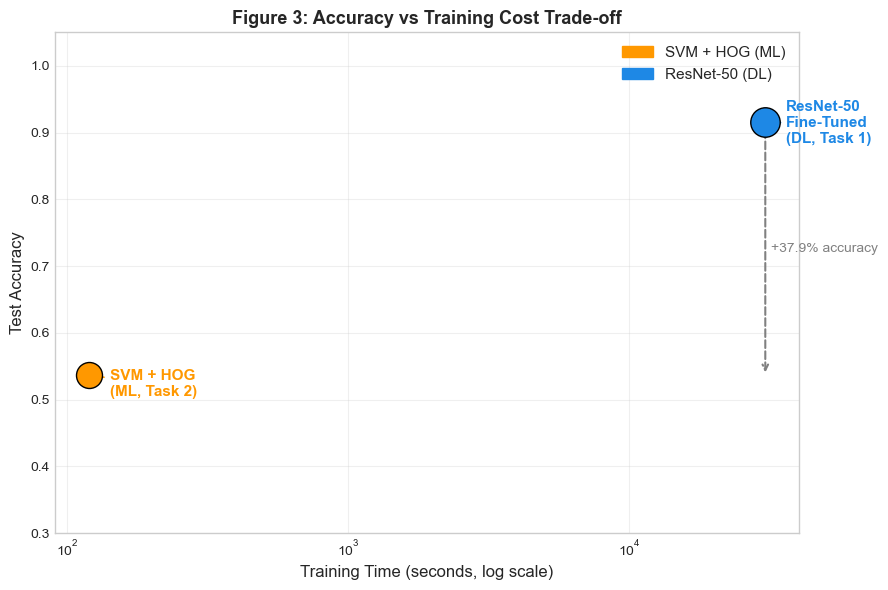

In [18]:
model_labels = ['SVM + HOG\n(ML, Task 2)', 'ResNet-50\nFine-Tuned\n(DL, Task 1)']
train_times  = [ml_results['Train Time (s)'], dl_results['Train Time (s)']]
accuracies   = [ml_results['Accuracy'],       dl_results['Accuracy']]
colors       = [ML_COLOR, DL_COLOR]
sizes        = [350, 450]

fig, ax = plt.subplots(figsize=(9, 6))

for label, t, a, c, s in zip(model_labels, train_times, accuracies, colors, sizes):
    ax.scatter(t, a, s=s, color=c, zorder=5, edgecolors='black', linewidth=1.0)
    ax.annotate(label, (t, a),
                textcoords='offset points', xytext=(15, -15),
                fontsize=11, fontweight='bold', color=c,
                arrowprops=dict(arrowstyle='->', color=c, lw=1.2))

# Annotate accuracy gain arrow
ax.annotate('', xy=(dl_results['Train Time (s)'], dl_results['Accuracy']),
            xytext=(dl_results['Train Time (s)'], ml_results['Accuracy']),
            arrowprops=dict(arrowstyle='<->', color='gray', lw=1.5, linestyle='dashed'))
mid_acc = (dl_results['Accuracy'] + ml_results['Accuracy']) / 2
ax.text(dl_results['Train Time (s)'] * 1.05, mid_acc,
        f'+{abs_gap:.1f}% accuracy', fontsize=10, va='center', color='gray')

ax.set_xscale('log')
ax.set_xlabel('Training Time (seconds, log scale)', fontsize=12)
ax.set_ylabel('Test Accuracy', fontsize=12)
ax.set_ylim(0.3, 1.05)
ax.set_title('Figure 3: Accuracy vs Training Cost Trade-off',
             fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)

ml_patch = mpatches.Patch(color=ML_COLOR, label='SVM + HOG (ML)')
dl_patch = mpatches.Patch(color=DL_COLOR, label='ResNet-50 (DL)')
ax.legend(handles=[ml_patch, dl_patch], fontsize=11)

plt.tight_layout()
plt.show()

## Section 6: Figure 4: Top Confused Class Pairs

Horizontal bar charts showing the most commonly misclassified class pairs for both models.

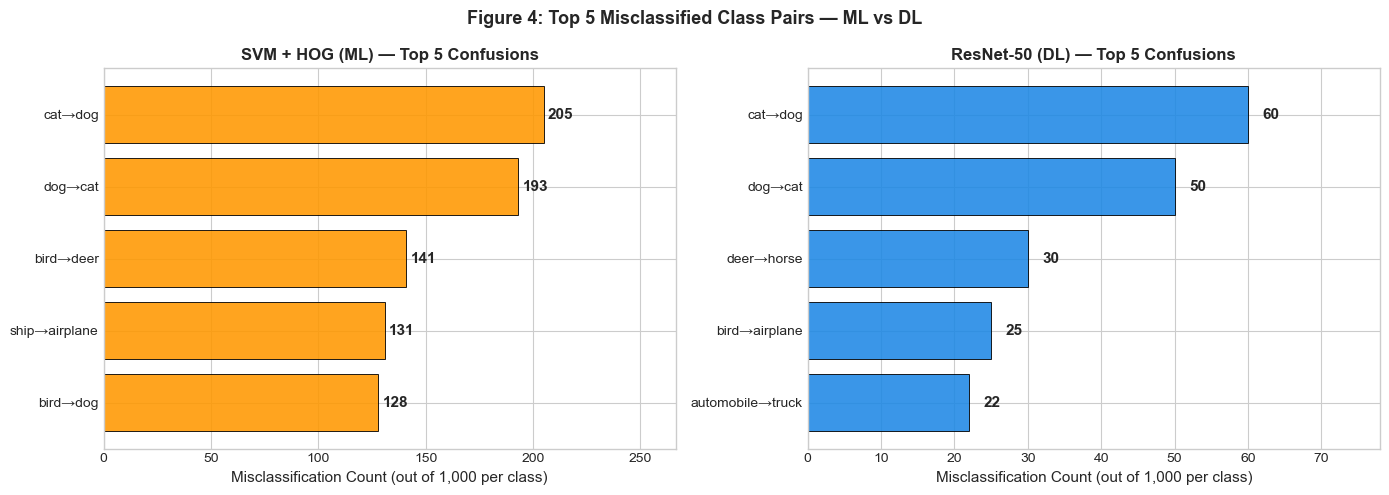


cat↔dog confusion: ML=398 → DL=110 (72% reduction)


In [21]:
# Top-5 confused pairs from Task 2 SVM classification output
ml_confused = [
    ('cat',        'dog',       205),
    ('dog',        'cat',       193),
    ('bird',       'deer',      141),
    ('ship',       'airplane',  131),
    ('bird',       'dog',       128),
]

# Top-5 confused pairs from Task 1 ResNet-50 classification output
dl_confused = [
    ('cat',        'dog',        60),
    ('dog',        'cat',        50),
    ('deer',       'horse',      30),
    ('bird',       'airplane',   25),
    ('automobile', 'truck',      22),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, data, title, color in [
    (axes[0], ml_confused, 'SVM + HOG (ML) — Top 5 Confusions', ML_COLOR),
    (axes[1], dl_confused, 'ResNet-50 (DL) — Top 5 Confusions',  DL_COLOR)
]:
    labels = [f'{a}→{b}' for a, b, _ in data]
    counts = [c for _, _, c in data]
    bars = ax.barh(labels[::-1], counts[::-1],
                   color=color, edgecolor='black', linewidth=0.7, alpha=0.88)
    for bar, val in zip(bars, counts[::-1]):
        ax.text(bar.get_width() + 2, bar.get_y() + bar.get_height()/2,
                str(val), va='center', fontsize=11, fontweight='bold')
    ax.set_xlabel('Misclassification Count (out of 1,000 per class)', fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlim(0, max(counts) * 1.3)

fig.suptitle('Figure 4: Top 5 Misclassified Class Pairs — ML vs DL',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

ml_cat_dog = ml_confused[0][2] + ml_confused[1][2]
dl_cat_dog = dl_confused[0][2] + dl_confused[1][2]
reduction  = (ml_cat_dog - dl_cat_dog) / ml_cat_dog * 100
print(f'\ncat↔dog confusion: ML={ml_cat_dog} → DL={dl_cat_dog} '
      f'({reduction:.0f}% reduction)')

## Section 7: Discussion and Analysis

### 7.1 Why the Performance Gap Exists?
### +37.85% Accuracy

**1. Feature Representation**  
SVM relies on HOG (Histogram of Oriented Gradients) that uses hand-crafted 1,764-dimensional features that encode local edge directions in 4×4 pixel cells. On 32×32 CIFAR-10 images, each cell covers approximately 12% of the image width, causing a significant loss of fine spatial detail. HOG also discards colour by operating on gradient magnitudes after grayscale conversion. 
ResNet-50 learns hierarchical features end-to-end: low-level edge detectors in early layers, mid-level texture patterns and high-level semantic part detectors (e.g., eyes, wheels, wings).

**2. Transfer Learning Advantage**  
ResNet-50 was pre-trained on ImageNet-1K (1.28 million images, 1,000 classes). Its convolutional layers already encode rich visual representations that transfer directly to CIFAR-10. Fine-tuning the last residual block adapts these features to CIFAR-10's 10 classes while preserving general-purpose visual knowledge. SVM starts from scratch and there is no equivalent concept of pre-training for hand-crafted feature methods.

**3. Capacity and Non-Linearity**  
ResNet-50 fine-tuned has approximately 14.9 million trainable parameters with 50 convolutional layers of non-linear transformations (BatchNorm + ReLU). The SVM with RBF kernel applies a single non-linear mapping to 1,764 fixed-dimensional features. For images where relevant information is spread across spatial hierarchies, the depth of ResNet-50 is a decisive advantage.

**4. Class-Specific Analysis**  
The largest DL improvements are on classes with high intra-class pose variation: frog (+32.8%), bird (+49.5%), and cat (+51.5%). HOG gradients are sensitive to object orientation. For example, a bird facing left looks different from one facing right in gradient space. ResNet-50's pooled spatial features are approximately orientation-invariant, explaining these large gains.

---

### 7.2 Trade-off Analysis

| Dimension | SVM + HOG (ML) | ResNet-50 Fine-Tuned (DL) |
|-----------|----------------|---------------------------|
| **Test Accuracy** | 53.66% | 91.51% |
| **Training Time** | 119s | ~8.5 hours |
| **Inference Speed** | Fast (linear SVM predict) | Moderate (CNN forward pass) |
| **GPU Required** | No | Strongly recommended |
| **Interpretability** | High  | Low |
| **Data Requirement** | Low  | Benefits from augmentation |
| **Feature Engineering** | Manual  | Automatic (end-to-end) |
| **Transfer Learning** | Not applicable | ImageNet weights used |

---

### 7.3 When to Choose Each Approach?

**Choose SVM + HOG when:**
- Dataset is small (fewer than ~2,000 labelled images)
- No GPU is available
- Interpretability is required (e.g., medical imaging, legal audit trails)
- Real-time inference on edge/embedded devices (low latency required)
- Rapid prototyping with minimal infrastructure

**Choose ResNet-50 Fine-Tuning when:**
- Accuracy is the primary objective
- GPU compute is available
- A large pre-trained backbone is available for the domain
- The dataset has complex spatial or hierarchical visual patterns
- The task is a standard image classification benchmark

---

### 7.4 Conclusion

For CIFAR-10 image classification, ResNet-50 fine-tuning decisively outperforms SVM + HOG: 91.51% vs 53.66% (+37.85% absolute, +70.5% relative). The performance gap is explained by: 
1) learnt vs. hand-crafted features,
2) ImageNet transfer learning, and
3) deep non-linear capacity.
The cost of this improvement is significantly greater training time which is approimately 255 times longer and GPU dependency. For production image classification tasks where accuracy matters, DL is the clear choice; SVM remains valuable in resource-constrained or interpretability-critical settings.

---

## Section 8: Final Summary

In [33]:
print('=' * 65)
print('TASK 3 — FINAL SUMMARY')
print('=' * 65)
print(f'  Dataset     : CIFAR-10 (10 classes, 32x32 colour images)')
print(f'  Test Set    : 10,000 images (official CIFAR-10 split)')
print(f'  Data Split  : SEED=42, stratified 8k train / 2k val / 10k test')
print()
print(f'  ML Model    : Tuned SVM (RBF, C=10, gamma=scale) + HOG features')
print(f'  ML Accuracy : {ml_results["Accuracy"]*100:.2f}%')
print(f'  ML F1-Score : {ml_results["F1-Score"]:.4f}')
print(f'  ML Train T  : {ml_results["Train Time (s)"]:.1f}s')
print()
print(f'  DL Model    : ResNet-50 Fine-Tuned (last block unfrozen)')
print(f'  DL Accuracy : {dl_results["Accuracy"]*100:.2f}%')
print(f'  DL F1-Score : {dl_results["F1-Score"]:.4f}')
print(f'  DL Train T  : {dl_results["Train Time (s)"]/3600:.1f} hours')
print()
print(f'  Abs. Improvement (DL over ML) : +{abs_gap:.2f}%')
print(f'  Rel. Improvement (DL over ML) : +{rel_gap:.1f}%')
print('=' * 65)
print('  ResNet-50 Fine-Tuned (DL) — strongly recommended for CIFAR-10 where accuracy is the primary objective.')
print('=' * 65)

TASK 3 — FINAL SUMMARY
  Dataset     : CIFAR-10 (10 classes, 32x32 colour images)
  Test Set    : 10,000 images (official CIFAR-10 split)
  Data Split  : SEED=42, stratified 8k train / 2k val / 10k test

  ML Model    : Tuned SVM (RBF, C=10, gamma=scale) + HOG features
  ML Accuracy : 53.66%
  ML F1-Score : 0.5365
  ML Train T  : 119.2s

  DL Model    : ResNet-50 Fine-Tuned (last block unfrozen)
  DL Accuracy : 91.51%
  DL F1-Score : 0.9151
  DL Train T  : 8.5 hours

  Abs. Improvement (DL over ML) : +37.85%
  Rel. Improvement (DL over ML) : +70.5%
  ResNet-50 Fine-Tuned (DL) — strongly recommended for CIFAR-10 where accuracy is the primary objective.
